# Natural policy gradient on a gridworld

Continuation of the bandit notebook, with a genuine MDP. Everything below is driven by the variables in the **configuration cell**:
change the grid size, the positions or the number of bonus squares and pits, the rewards, the discount, the slip probability or any
algorithm setting there, then *Run All*. The text refers to these variables by name and never to their values; the actual numbers are
printed by the code cells.

**The environment.** The agent starts at `START_CELL` and moves with the actions in `MOVES`. Every move pays `R_STEP`.
Entering `GOAL_CELL` pays `R_GOAL` and ends the episode, entering a cell of `PIT_CELLS` pays `R_PIT` and ends the episode.
Entering a bonus square pays `R_BONUS` the *first* time in an episode, and the episode continues. To keep the problem Markov, the state is
$s=(\text{cell},\text{mask})$, where bit $i$ of the mask records whether bonus $i$ was already collected. Only reachable states are kept.
With probability `SLIP_PROB` the executed action is replaced by a uniformly random one. Returns are discounted by `GAMMA`.

**How it connects to the notes.**

| Notes | Here |
|---|---|
| $M$, manifold of policies | all strictly positive tabular policies $\pi(a\mid s)$, $\dim M=|S|\,(|A|-1)$ (`N_PARAMS`) |
| chart $\theta$ | $\theta_{s,a}=\log\pi(a\mid s)-\log\pi(a_{\rm ref}\mid s)$ for $a\ne a_{\rm ref}$ (see Section 2) |
| $\eta$ | expected discounted return from the start state |
| $\rho_p$ | discounted state distribution $d(s)=u(s)/\sum_{s'}u(s')$, $u(s)=\sum_t\gamma^t\Pr(s_t=s)$ |
| $F_p$, $\operatorname{grad}_F\eta$ | Fisher metric, natural gradient (Sections 3 and 6) |

In [37]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# =========================================================================================
#                         CONFIGURATION: edit here, then "Run All"
# =========================================================================================
# ---- grid ----------------------------------------------------------------------------
ROWS, COLS  = 5, 5
START_CELL  = (0, 0)
GOAL_CELL   = (ROWS - 1, COLS - 1)

# ---- bonus squares and pits ----------------------------------------------------------
LAYOUT      = "random"                       # "manual": use the two lists below
                                             # "random": draw N_BONUS and N_PITS free cells (seeded)
BONUS_CELLS = [(1, 3), (3, 0)]               # used when LAYOUT == "manual"
PIT_CELLS   = [(1, 1), (2, 3), (3, 1)]       # used when LAYOUT == "manual"
N_BONUS, N_PITS = 3, 5                       # used when LAYOUT == "random"
LAYOUT_SEED = 1

# ---- rewards -------------------------------------------------------------------------
R_STEP  = -1.0      # paid on every move, including a move into a wall
R_GOAL  = 100.0     # entering the goal (episode ends)
R_PIT   = -50.0     # entering a pit (episode ends)
R_BONUS = 30.0      # entering a bonus square for the first time in an episode (episode continues)

# ---- dynamics ------------------------------------------------------------------------
GAMMA       = 0.95  # discount factor
SLIP_PROB   = 0.0   # with this probability the chosen action is replaced by a uniformly random one
MOVES        = [(-1, 0), (1, 0), (0, -1), (0, 1)]       # (d_row, d_col) of each action
ACTION_NAMES = ["up", "down", "left", "right"]
REF_ACTION   = len(MOVES) - 1                           # the action whose logit is fixed to 0 in every state

# ---- policy initialisation -----------------------------------------------------------
INIT_STD    = 0.0   # std of random initial coordinates theta (0.0 = uniform random policy)
INIT_SEED   = 0     # seed for the initial coordinates when INIT_STD > 0

# ---- sampling ------------------------------------------------------------------------
MAX_STEPS           = 1000    # episodes are cut after this many moves
EPISODES_PER_ITER   = 3000     # episodes sampled per policy update
BASELINE            = "exact"   # "exact": subtract V^pi(s) (exact, state-only);  "none": no baseline

# ---- optimisation experiments --------------------------------------------------------
N_ITERS         = 15                          # policy updates per sampled run
N_ITERS_EXACT   = 300                          # policy updates per noise-free (exact-gradient) run
N_SEEDS         = 10                           # independent sampled runs per configuration
CHECK_EPISODES  = 4000                         # batch size used once to compare sampled estimators with exact values
CHART_SCALE_SPREAD = 3.0                       # chart test: coordinates rescaled by factors in [1/spread, spread]
LR_GRID     = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]  # vanilla learning rates to try
EPS_GRID    = [0.003, 0.01, 0.03, 0.1, 0.3]            # natural-gradient KL budgets to try
DAMPING     = 0.05          # max ridge in the *per-state conditional* Fisher system
MIN_EFFECTIVE_VISITS = 10.0 # shrink sampled state updates when local effective sample count is small
MAX_LOGIT_STEP = 50.0       # no update may change any coordinate theta_{s,a} by more than this (None = no cap).
                            # Safeguard for near-deterministic policies, where the KL-budget step size blows up.
SUCCESS_FRAC = 0.95         # "solved" = reaching eta_init + SUCCESS_FRAC * (eta_star - eta_init)

## 1. Layout and MDP

The cell below builds the MDP from the configuration: it validates the layout (distinct free cells, goal and all bonus squares reachable
without crossing a pit), enumerates the reachable states $s=(\text{cell},\text{mask})$ and tabulates the transitions. In `"random"` layout
mode it draws `N_BONUS` bonus squares and `N_PITS` pits with `LAYOUT_SEED`.

grid 5x5, start (0, 0), goal (4, 4)
bonus squares (3): [(2, 4), (0, 1), (2, 3)]   pits (5): [(3, 3), (4, 1), (3, 4), (1, 1), (2, 2)]
rewards: step -1, goal +100, pit -50, bonus +30;  gamma = 0.95;  slip = 0.0
decision states |S| = 82  (cells x collected-bonus masks, reachable only);  actions |A| = 4
manifold dimension = |S| (|A| - 1) = 246   (reference action: 'right')


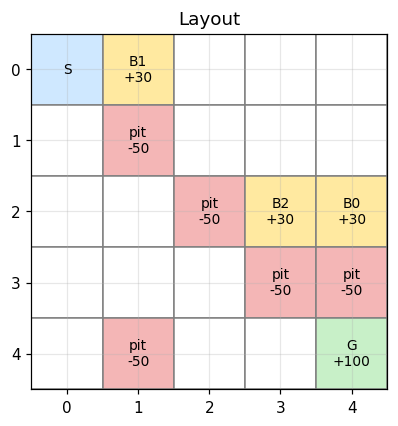

In [38]:
A_DIM = len(MOVES)
assert len(ACTION_NAMES) == A_DIM and 0 <= REF_ACTION < A_DIM

def inside(cell):
    return 0 <= cell[0] < ROWS and 0 <= cell[1] < COLS

def layout_is_valid(bonus, pits):
    """Cells distinct and free; goal and every bonus square reachable from the start without entering a pit."""
    cells = list(bonus) + list(pits)
    if len(set(cells)) != len(cells): return False
    if any((not inside(c)) or c in (START_CELL, GOAL_CELL) for c in cells): return False
    seen, stack = {START_CELL}, [START_CELL]
    while stack:                                       # pits and the goal end the episode, so they are not expanded
        cell = stack.pop()
        if cell == GOAL_CELL: continue
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            if inside(nxt) and nxt not in seen and nxt not in pits:
                seen.add(nxt); stack.append(nxt)
    return GOAL_CELL in seen and all(b in seen for b in bonus)

def make_layout():
    if LAYOUT == "manual":
        bonus, pits = list(BONUS_CELLS), list(PIT_CELLS)
        if not layout_is_valid(bonus, pits):
            raise ValueError("Manual layout is invalid: overlapping/out-of-grid cells, or goal/bonus unreachable.")
        return bonus, pits
    rng = np.random.default_rng(LAYOUT_SEED)
    free = [(r, c) for r in range(ROWS) for c in range(COLS) if (r, c) not in (START_CELL, GOAL_CELL)]
    for _ in range(100_000):
        pick = [free[i] for i in rng.permutation(len(free))[:N_BONUS + N_PITS]]
        if layout_is_valid(pick[:N_BONUS], pick[N_BONUS:]):
            return pick[:N_BONUS], pick[N_BONUS:]
    raise RuntimeError("Could not find a valid random layout; reduce N_BONUS / N_PITS.")

BONUS, PITS = make_layout()
BONUS_INDEX = {cell: i for i, cell in enumerate(BONUS)}      # bit i of the "mask" = bonus i already collected
PIT_SET = set(PITS)

def transition_det(cell, mask, a, r_bonus):
    """Deterministic effect of performing action a in state (cell, mask)."""
    dr, dc = MOVES[a]
    new = (cell[0] + dr, cell[1] + dc)
    if not inside(new): new = cell                            # bump into the wall: stay
    reward, terminal, new_mask = R_STEP, False, mask
    if new == GOAL_CELL:   reward += R_GOAL; terminal = True
    elif new in PIT_SET:   reward += R_PIT;  terminal = True
    if new in BONUS_INDEX and not (mask >> BONUS_INDEX[new]) & 1:
        reward += r_bonus; new_mask = mask | (1 << BONUS_INDEX[new])
    return new, new_mask, reward, terminal

# State = (cell, mask).  Enumerate the states reachable from the start (breadth-first).
STATES = [(START_CELL, 0)]
INDEX = {STATES[0]: 0}
ptr = 0
while ptr < len(STATES):
    cell, mask = STATES[ptr]; ptr += 1
    for a in range(A_DIM):
        new, new_mask, _, terminal = transition_det(cell, mask, a, R_BONUS)
        if not terminal and (new, new_mask) not in INDEX:
            INDEX[(new, new_mask)] = len(STATES); STATES.append((new, new_mask))
S = len(STATES)                  # number of (non-terminal) states
S0 = 0                           # index of the start state
OTHER = [a for a in range(A_DIM) if a != REF_ACTION]       # actions whose coordinate theta_{s,a} is a free parameter
N_FREE = A_DIM - 1               # dim of the probability simplex at one state
N_PARAMS = S * N_FREE            # dim of the manifold M = number of coordinates

def build_arrays(r_bonus):
    """NEXT[s, b] = next state index (S = terminal sink), REW[s, b] = reward, for the effective action b."""
    NEXT = np.full((S, A_DIM), S, dtype=int); REW = np.zeros((S, A_DIM))
    for (cell, mask), i in INDEX.items():
        for b in range(A_DIM):
            new, new_mask, rew, terminal = transition_det(cell, mask, b, r_bonus)
            NEXT[i, b] = S if terminal else INDEX[(new, new_mask)]
            REW[i, b] = rew
    return NEXT, REW

NEXT_DET, REW_DET = build_arrays(R_BONUS)
KMAT = (1 - SLIP_PROB) * np.eye(A_DIM) + SLIP_PROB / A_DIM    # KMAT[a, b] = P(effective action b | chosen action a)

def draw_layout(ax, title=None):
    ax.set_xlim(-0.5, COLS - 0.5); ax.set_ylim(ROWS - 0.5, -0.5); ax.set_aspect("equal")
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS)); ax.grid(True, alpha=0.3)
    for r in range(ROWS):
        for c in range(COLS):
            cell = (r, c); col, txt = "white", ""
            if cell == START_CELL: col, txt = "#cfe8ff", "S"
            if cell == GOAL_CELL:  col, txt = "#c8f0c8", f"G\n{R_GOAL:+g}"
            if cell in PIT_SET:    col, txt = "#f4b6b6", f"pit\n{R_PIT:+g}"
            if cell in BONUS_INDEX: col, txt = "#ffe9a0", f"B{BONUS_INDEX[cell]}\n{R_BONUS:+g}"
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc=col, ec="gray"))
            ax.text(c, r, txt, ha="center", va="center", fontsize=9)
    if title: ax.set_title(title)

print(f"grid {ROWS}x{COLS}, start {START_CELL}, goal {GOAL_CELL}")
print(f"bonus squares ({len(BONUS)}): {BONUS}   pits ({len(PITS)}): {PITS}")
print(f"rewards: step {R_STEP:+g}, goal {R_GOAL:+g}, pit {R_PIT:+g}, bonus {R_BONUS:+g};  gamma = {GAMMA};  slip = {SLIP_PROB}")
print(f"decision states |S| = {S}  (cells x collected-bonus masks, reachable only);  actions |A| = {A_DIM}")
print(f"manifold dimension = |S| (|A| - 1) = {N_PARAMS}   (reference action: '{ACTION_NAMES[REF_ACTION]}')")
fig, ax = plt.subplots(figsize=(4.2, 4.2)); draw_layout(ax, "Layout"); plt.show()

## 2. The chart: why one logit per state is fixed

The map "state $\mapsto$ all $|A|$ softmax logits" is **not a chart** in the sense of Step 2 of the notes: adding the same constant to all
logits of a state leaves $\pi(\cdot\mid s)$ unchanged, so it is not injective, and the parameter space has more dimensions than $M$.
(The consequence was a Fisher matrix with a kernel, which is why the bandit notebook needed a pseudoinverse.)

Fix a reference action $a_{\rm ref}$ (`REF_ACTION`) and define, for $a\neq a_{\rm ref}$,
$$\theta_{s,a}=\log\pi(a\mid s)-\log\pi(a_{\rm ref}\mid s),\qquad \theta^{-1}:\ \pi(a\mid s)=\frac{e^{\theta_{s,a}}}{1+\sum_{b\ne a_{\rm ref}}e^{\theta_{s,b}}}\ \ (\text{and } \theta_{s,a_{\rm ref}}:=0).$$
This is a bijection between $M$ (a product of $|S|$ open simplices) and $\mathbb R^{|S|(|A|-1)}$. Consequences:

- the Fisher matrix in this chart is **positive definite** (on every state with $d(s)>0$), so $F^{-1}$ exists and no pseudoinverse is needed;
- $\operatorname{grad}_F\eta$ has components $w_{s,a}=A(s,a)-A(s,a_{\rm ref})$. This is the *same vector* as "advantage up to a per-state constant" from the bandit
  analysis; the constant is now fixed by the chart (the $a_{\rm ref}$ component is zero).

In [39]:
# ---------------- the chart: theta[s, j] = log pi(OTHER[j] | s) - log pi(REF_ACTION | s) ----------------
def logits_from_theta(theta):
    Z = np.zeros((S, A_DIM)); Z[:, OTHER] = theta; return Z       # the reference logit is 0

def softmax_rows(Z):
    E = np.exp(Z - Z.max(1, keepdims=True)); return E / E.sum(1, keepdims=True)

def policy_from_theta(theta):                 # theta^{-1}: coordinates -> policy
    return softmax_rows(logits_from_theta(theta))

def theta_from_policy(pi):                    # theta: policy -> coordinates
    return np.log(pi[:, OTHER]) - np.log(pi[:, [REF_ACTION]])

# ---------------- exact policy evaluation (finite MDP, linear algebra) ----------------
def evaluate(pi, NEXT=None, REW=None):
    """Return V, Q (for the CHOSEN action) and u(s) = sum_t gamma^t Pr(s_t = s), starting from S0."""
    NEXT = NEXT_DET if NEXT is None else NEXT
    REW = REW_DET if REW is None else REW
    pi_eff = (1 - SLIP_PROB) * pi + SLIP_PROB / A_DIM            # distribution of the action actually executed
    P = np.zeros((S, S))
    for b in range(A_DIM):
        rows = np.flatnonzero(NEXT[:, b] < S)
        np.add.at(P, (rows, NEXT[rows, b]), pi_eff[rows, b])
    r = (pi_eff * REW).sum(1)
    V = np.linalg.solve(np.eye(S) - GAMMA * P, r)
    Qb = REW + GAMMA * np.append(V, 0.0)[NEXT]                    # value of executing action b
    Q = Qb @ KMAT.T                                               # value of CHOOSING action a
    e0 = np.zeros(S); e0[S0] = 1.0
    u = np.linalg.solve(np.eye(S) - GAMMA * P.T, e0)
    return V, Q, u

def value_iteration(NEXT=None, REW=None, iters=3000):
    NEXT = NEXT_DET if NEXT is None else NEXT
    REW = REW_DET if REW is None else REW
    V = np.zeros(S)
    for _ in range(iters):
        Q = (REW + GAMMA * np.append(V, 0.0)[NEXT]) @ KMAT.T
        V = Q.max(1)
    pi = np.zeros((S, A_DIM)); pi[np.arange(S), Q.argmax(1)] = 1.0
    return V, pi

def eta(pi):                                  # expected discounted return from the start state
    return evaluate(pi)[0][S0]

def greedy_route(pi):
    """Follow argmax actions from the start (ignoring slips). Returns (reached_goal, n_bonus_collected, cells)."""
    cell, mask, cells = START_CELL, 0, [START_CELL]
    for _ in range(MAX_STEPS):
        a = int(np.argmax(pi[INDEX[(cell, mask)]]))
        new, mask, _, terminal = transition_det(cell, mask, a, R_BONUS)
        cells.append(new); cell = new
        if terminal: return new == GOAL_CELL, bin(mask).count("1"), cells
    return False, bin(mask).count("1"), cells

# ---------------- reference values ----------------
def init_theta():
    if INIT_STD == 0.0: return np.zeros((S, N_FREE))
    return INIT_STD * np.random.default_rng(INIT_SEED).standard_normal((S, N_FREE))

THETA_INIT = init_theta()
PI_INIT = policy_from_theta(THETA_INIT)
ETA_INIT = eta(PI_INIT)
V_STAR, PI_STAR = value_iteration()
ETA_STAR = V_STAR[S0]
_nb_next, _nb_rew = build_arrays(0.0)                     # same MDP but the bonuses pay nothing...
_, PI_NOBONUS = value_iteration(_nb_next, _nb_rew)        # ...optimal policy there, evaluated in the REAL MDP:
ETA_NOBONUS = eta(PI_NOBONUS)
TARGET = ETA_INIT + SUCCESS_FRAC * (ETA_STAR - ETA_INIT)

print(f"eta(initial policy)                 = {ETA_INIT:9.3f}")
print(f"eta* (optimal)                      = {ETA_STAR:9.3f}")
print(f"eta of best policy ignoring bonuses = {ETA_NOBONUS:9.3f}   (a method that only finds the goal ends near here)")
print(f"success target                      = {TARGET:9.3f}   ({SUCCESS_FRAC:.0%} of the way from initial to optimal)")
ok, nb, cells = greedy_route(PI_STAR)
print(f"optimal route: {cells}  ->  goal reached: {ok}, bonuses collected: {nb} of {len(BONUS)}")

eta(initial policy)                 =   -22.892
eta* (optimal)                      =   102.554
eta of best policy ignoring bonuses =    63.102   (a method that only finds the goal ends near here)
success target                      =    96.281   (95% of the way from initial to optimal)
optimal route: [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (2, 4), (1, 4), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (4, 2), (4, 3), (4, 4)]  ->  goal reached: True, bonuses collected: 3 of 3


## 3. Exact objects: gradient, Fisher metric, natural gradient

Everything is a finite linear-algebra problem, so we can compute the exact quantities as ground truth.
With $P_\pi$ the state transition matrix under $\pi$ and $e_{s_0}$ the start indicator,
$$V^\pi=(I-\gamma P_\pi)^{-1}r_\pi,\qquad u=(I-\gamma P_\pi^\top)^{-1}e_{s_0},\qquad A(s,a)=Q^\pi(s,a)-V^\pi(s).$$

- **Differential of $\eta$** (policy gradient theorem), components in the chart $\theta$: $\ \dfrac{\partial\eta}{\partial\theta_{s,a}}=u(s)\,\pi(a\mid s)\,A(s,a)$.
- **Fisher metric** (Step 19, with the normalised weights $d$): block diagonal, one block per state,
  $F_s=d(s)\big(\operatorname{diag}(\pi_{\rm free})-\pi_{\rm free}\pi_{\rm free}^\top\big)$, where $\pi_{\rm free}$ collects $\pi(a\mid s)$ for $a\ne a_{\rm ref}$.
  Its quadratic form is $F(w,w)=\sum_s d(s)\operatorname{Var}_{a\sim\pi(\cdot|s)}[w(s,a)]$ with $w(s,a_{\rm ref})=0$.
- **Natural gradient:** $w=F^{-1}g_K$ with $g_K=\big(d(s)\pi(a\mid s)A(s,a)\big)_{s,a}$, which has the closed form $w_{s,a}=A(s,a)-A(s,a_{\rm ref})$. The weight $d(s)$ cancels.
- **Step:** displacement $\alpha w$ with $\alpha=\sqrt{2\varepsilon/F(w,w)}$, i.e. a mean KL (under $d$) of about $\varepsilon$ per update.

The checks below confirm the formulas numerically on a random policy.

In [40]:
def exact_objects(pi):
    V, Q, u = evaluate(pi)
    A = Q - V[:, None]                         # advantage A(s, a)
    d = u / u.sum()                            # normalised discounted state distribution
    return V, A, u, d

def exact_grad(pi):
    """Components of d(eta) in the chart theta: u(s) pi(a|s) A(s,a), for the free actions a."""
    V, A, u, d = exact_objects(pi)
    return (u[:, None] * pi * A)[:, OTHER]

def fisher_matrix(pi, d):
    """F in the chart theta: block diagonal, block s = d(s) (diag(pi_o) - pi_o pi_o^T).  Shape (N_PARAMS, N_PARAMS)."""
    F = np.zeros((N_PARAMS, N_PARAMS))
    for s in range(S):
        p = pi[s, OTHER]; sl = slice(s * N_FREE, (s + 1) * N_FREE)
        F[sl, sl] = d[s] * (np.diag(p) - np.outer(p, p))
    return F

def exact_natural(pi):
    """Closed form of F^{-1} g_K in the chart theta:  w[s, a] = A(s, a) - A(s, REF_ACTION), a != REF_ACTION."""
    V, A, u, d = exact_objects(pi)
    return A[:, OTHER] - A[:, [REF_ACTION]]

def fisher_quad(pi, W):
    """F(w, w) = sum_s d(s) Var_{a~pi(.|s)}[w(s, a)]  (with w(s, REF_ACTION) = 0). The mean KL per unit step^2 / 2."""
    V, A, u, d = exact_objects(pi)
    p = pi[:, OTHER]
    return float(np.sum(d * ((p * W**2).sum(1) - ((p * W).sum(1))**2)))

# ---- checks on a random (strictly positive) policy ----
rng_chk = np.random.default_rng(1)
th_chk = rng_chk.normal(size=(S, N_FREE)); pi_chk = policy_from_theta(th_chk)
g_chk = exact_grad(pi_chk)

def J_of(theta): return eta(policy_from_theta(theta))
g_num = np.zeros_like(th_chk)
for s in range(S):
    for j in range(N_FREE):
        dlt = np.zeros_like(th_chk); dlt[s, j] = 1e-6
        g_num[s, j] = (J_of(th_chk + dlt) - J_of(th_chk - dlt)) / 2e-6
print("exact gradient vs finite differences, max abs error:", np.abs(g_chk - g_num).max())

V_, A_, u_, d_ = exact_objects(pi_chk)
F_chk = fisher_matrix(pi_chk, d_)
eig = np.linalg.eigvalsh(F_chk)
print(f"Fisher matrix {F_chk.shape}: smallest eigenvalue = {eig.min():.3e} (> 0: positive definite, no kernel), largest = {eig.max():.3e}")
gK_chk = (d_[:, None] * pi_chk * A_)[:, OTHER]            # g_K = d(eta) / sum(u): the gradient under the normalised weights d
w_solve = np.linalg.solve(F_chk, gK_chk.ravel()).reshape(S, N_FREE)
print("natural gradient: linear solve vs closed form A(s,a) - A(s,ref), max abs diff:",
      np.abs(w_solve - exact_natural(pi_chk)).max())

exact gradient vs finite differences, max abs error: 1.0331410574271338e-08
Fisher matrix (246, 246): smallest eigenvalue = 1.972e-12 (> 0: positive definite, no kernel), largest = 8.090e-02
natural gradient: linear solve vs closed form A(s,a) - A(s,ref), max abs diff: 1.0664818824325173e-13


## 4. Who gets updated?

For vanilla ascent the update at state $s$ is proportional to $u(s)\pi(a\mid s)A(s,a)$: states that are rarely visited from the start receive tiny updates.
The natural direction has no $u(s)$ factor. The maps below show, for the initial policy, the visitation, the size of the vanilla update and the size of the natural update
in each cell (states where no bonus has been collected yet, i.e. `mask = 0`).

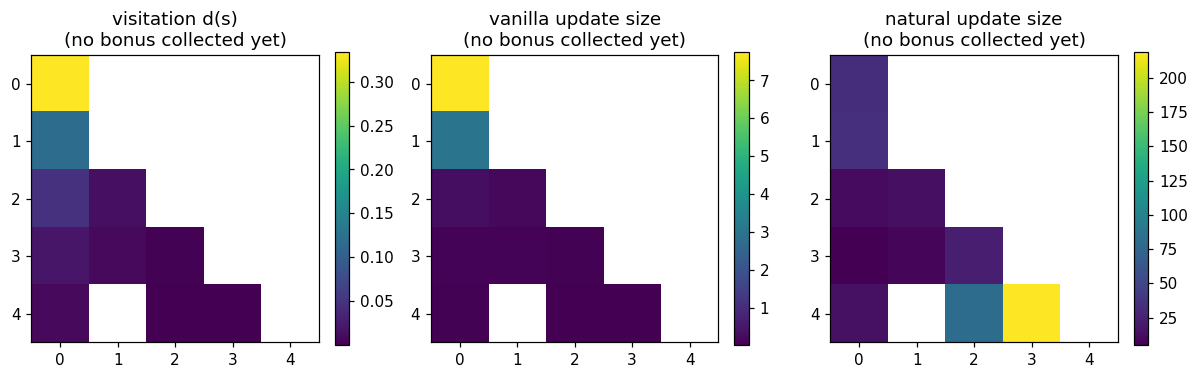

In [41]:
# Where does each method put its update?  Compare, at the initial policy, the size of the update in each cell.
def per_cell(values_per_state, mask=0):
    """Arrange a per-state quantity on the grid for the given bonus mask (NaN where that state does not exist)."""
    M = np.full((ROWS, COLS), np.nan)
    for (cell, m), i in INDEX.items():
        if m == mask: M[cell] = values_per_state[i]
    return M

V0, A0, u0, d0 = exact_objects(PI_INIT)
g0 = exact_grad(PI_INIT); w0 = exact_natural(PI_INIT)
vanilla_size = np.linalg.norm(g0, axis=1)               # |update| per state, vanilla direction
natural_size = np.linalg.norm(w0, axis=1)               # |update| per state, natural direction

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, vals, name in zip(axes, [d0, vanilla_size, natural_size],
                          ["visitation d(s)", "vanilla update size", "natural update size"]):
    im = ax.imshow(per_cell(vals), cmap="viridis"); ax.set_title(name + "\n(no bonus collected yet)")
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS)); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 5. Experiment A: noise-free comparison (exact gradient, exact natural gradient)

First remove all sampling noise: at each iteration use the exact $d\eta$ and the exact $\operatorname{grad}_F\eta$. This isolates the *geometry* of the two update rules.
Both methods use the same safeguard `MAX_LOGIT_STEP` (no coordinate moves by more than that in one update), which is only active when the KL-budget step $\alpha$ explodes on
near-deterministic policies.

Reference levels in the plots: $\eta^*$ (solid), the best return achievable while ignoring the bonuses (dotted), and the success target (dashed).

In [42]:
def cap_step(step, scales):
    """Rescale an update so that no coordinate theta changes by more than MAX_LOGIT_STEP (direction unchanged)."""
    if MAX_LOGIT_STEP is None: return step
    m = np.max(np.abs(step / scales))
    return step if m <= MAX_LOGIT_STEP else step * (MAX_LOGIT_STEP / m)

def run_exact(method, n_iter, lr=None, eps=None, scales=None):
    """Noise-free optimisation: exact gradient / exact natural direction at every iteration.
    scales: optional positive vector; the chart is psi = scales * theta (a different parametrisation of the same policies)."""
    scales = np.ones(N_PARAMS) if scales is None else scales
    psi = (THETA_INIT.ravel() * scales); etas = []
    for k in range(n_iter):
        pi = policy_from_theta((psi / scales).reshape(S, N_FREE)); etas.append(eta(pi))
        if method == "vanilla":
            step = lr * (exact_grad(pi).ravel() / scales)            # components of the covector d(eta) in the chart psi
        else:
            W = exact_natural(pi)
            alpha = np.sqrt(2 * eps / max(fisher_quad(pi, W), 1e-300))
            step = alpha * (W.ravel() * scales)                      # components of the vector v_* in the chart psi
        psi = psi + cap_step(step, scales)
    etas.append(eta(policy_from_theta((psi / scales).reshape(S, N_FREE))))
    return np.array(etas)

def first_hit(curve, target):
    hit = np.flatnonzero(curve >= target)
    return int(hit[0]) if len(hit) else None

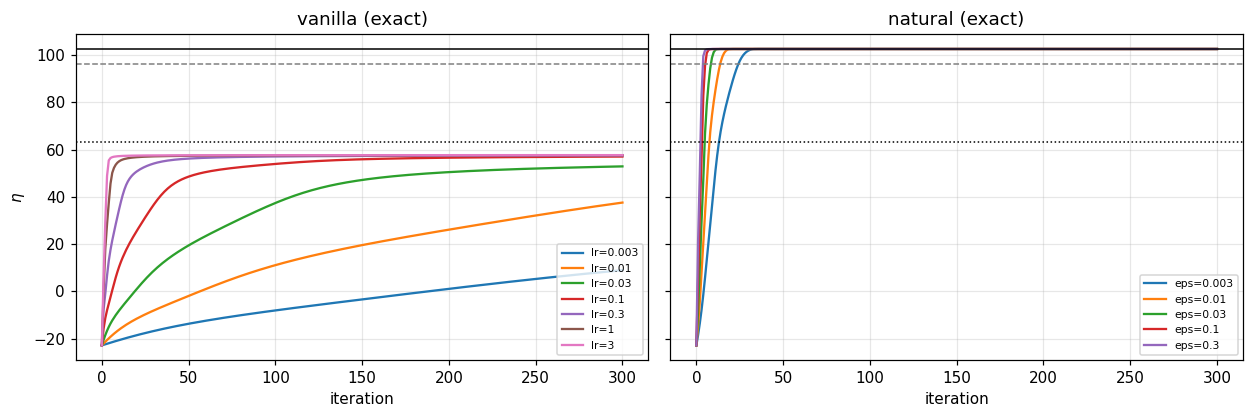

method      setting  final eta  gap closed   iterations to reach 50%  90%  95%  99%
vanilla    lr=0.003       8.93       25.4%       -      -      -      -
vanilla     lr=0.01      37.55       48.2%       -      -      -      -
vanilla     lr=0.03      52.86       60.4%     109      -      -      -
vanilla      lr=0.1      57.02       63.7%      34      -      -      -
vanilla      lr=0.3      57.48       64.1%      12      -      -      -
vanilla        lr=1      57.60       64.2%       5      -      -      -
vanilla        lr=3      57.63       64.2%       3      -      -      -
natural   eps=0.003     102.55      100.0%      10     22     25     29
natural    eps=0.01     102.55      100.0%       6     13     14     17
natural    eps=0.03     102.55      100.0%       4      8      9     11
natural     eps=0.1     102.55      100.0%       3      5      6      7
natural     eps=0.3     102.55      100.0%       2      4      4      5


In [43]:
FRACS = sorted(set([0.5, 0.9, SUCCESS_FRAC, 0.99]))
def level(f): return ETA_INIT + f * (ETA_STAR - ETA_INIT)

def exact_sweep():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True)
    rows = []
    for ax, method, grid, name in [(axes[0], "vanilla", LR_GRID, "lr"), (axes[1], "natural", EPS_GRID, "eps")]:
        for hp in grid:
            curve = run_exact(method, N_ITERS_EXACT, **{name: hp})
            ax.plot(curve, label=f"{name}={hp:g}")
            rows.append((method, f"{name}={hp:g}", curve))
        ax.axhline(ETA_STAR, color="k", lw=1); ax.axhline(ETA_NOBONUS, color="k", lw=1, ls=":")
        ax.axhline(TARGET, color="gray", lw=1, ls="--")
        ax.set_title(f"{method} (exact)"); ax.set_xlabel("iteration"); ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=.3)
    axes[0].set_ylabel(r"$\eta$"); plt.tight_layout(); plt.show()
    return rows

exact_rows = exact_sweep()
print(f"{'method':8s} {'setting':>10s} {'final eta':>10s} {'gap closed':>11s}   iterations to reach "
      + "  ".join(f"{f:.0%}" for f in FRACS))
for method, setting, curve in exact_rows:
    hits = [first_hit(curve, level(f)) for f in FRACS]
    print(f"{method:8s} {setting:>10s} {curve[-1]:10.2f} {(curve[-1]-ETA_INIT)/(ETA_STAR-ETA_INIT):11.1%}   "
          + "  ".join(f"{('-' if h is None else h):>5}" for h in hits))

**Reading the table.** "-" means the level was never reached within `N_ITERS_EXACT` iterations. Check two things: how many iterations each method needs to reach the high levels
(vanilla's gradient is multiplied by $\pi(a\mid s)$, so it slows down as the policy becomes deterministic), and whether a large learning rate ends on a policy that ignores the bonuses.

## 6. The sampled algorithm (statewise, damped natural gradient)

Each update collects `EPISODES_PER_ITER` on-policy episodes. The vanilla estimator is unchanged. For the natural gradient, we exploit the tabular Fisher matrix's block-diagonal structure, with one block per state.

For visits to state \(s\), form the *conditional* empirical Fisher block and score-return covariance:

$$
\widehat C_s =
\frac{\sum_{i:s_i=s}\gamma^{t_i}\phi_i\phi_i^\top}
{\sum_{i:s_i=s}\gamma^{t_i}},
\qquad
\widehat b_s =
\frac{\sum_{i:s_i=s}\gamma^{t_i}\widehat A_i\phi_i}
{\sum_{i:s_i=s}\gamma^{t_i}}.
$$

This normalization is important. The unconditioned block has the form $\widehat F_s=\widehat d_s\widehat C_s$, and its right-hand side has the same visitation-mass factor. Adding a fixed absolute ridge to $\widehat F_s$ makes rare states' updates collapse toward zero. Instead, we normalize the block by its observed mass before regularizing it.

We use a local, sample-count-adaptive ridge and confidence shrinkage:

$$
\lambda_s=\frac{\lambda_0}{\sqrt{n_{\rm eff}(s)}},
\qquad
c_s=\frac{n_{\rm eff}(s)}{n_{\rm eff}(s)+n_0},
\qquad
\widehat w_s=c_s(\widehat C_s+\lambda_s D_s^{-2})^{-1}\widehat b_s.
$$

Here $n_{\rm eff}$ is the effective number of discounted visits, `DAMPING` is $\lambda_0\$, and `MIN_EFFECTIVE_VISITS` is $n_0$. The ridge decreases and the confidence tends to one as a state's data accumulate, so (for states visited with positive probability) the estimator tends to the exact tabular natural direction. States never visited in a batch receive no update; damping cannot create information that was not sampled.

The KL/trust-region scale uses the *empirical Fisher only*:

$$
q=\widehat w^\top\widehat F\widehat w
=\sum_s\widehat d_s\widehat w_s^\top\widehat C_s\widehat w_s,
\qquad
\alpha=\sqrt{\frac{2\varepsilon}{q}}.
$$

The damping is a numerical/statistical regularizer, not part of the Fisher metric, and therefore is not included in \(q\). Score features are handled blockwise so the implementation avoids allocating a dense `(number of sampled steps) × N_PARAMS` matrix.

The simulator also bootstraps the value at the artificial `MAX_STEPS` cutoff using $V^\pi$, so the sampled returns target the same infinite-horizon discounted objective as exact evaluation.

In [44]:
def simulate(pi, n_ep, rng, bootstrap_V=None):
    """Sample episodes and return (state, chosen action, return-to-go, time).

    If a trajectory is truncated at MAX_STEPS rather than terminated by the MDP,
    bootstrap from bootstrap_V at the final nonterminal state. This aligns sampled
    returns with the infinite-horizon objective used by evaluate().
    """
    st = np.full(n_ep, S0, dtype=int)
    alive = np.ones(n_ep, dtype=bool)
    rec = []

    for t in range(MAX_STEPS):
        idx = np.flatnonzero(alive)
        if len(idx) == 0:
            break
        s = st[idx]
        a = np.minimum(
            (rng.random(len(idx))[:, None] > np.cumsum(pi[s], axis=1)).sum(axis=1),
            A_DIM - 1,
        )
        slipped = rng.random(len(idx)) < SLIP_PROB
        b = np.where(slipped, rng.integers(A_DIM, size=len(idx)), a)
        nxt, rew = NEXT_DET[s, b], REW_DET[s, b]
        rec.append((idx, t, s, a, rew))
        alive[idx] = nxt < S
        st[idx] = np.where(nxt < S, nxt, S0)

    # For truly terminal episodes the bootstrap remains zero. For episodes that
    # were still alive at the time limit, st is their final nonterminal state.
    G = np.zeros(n_ep, dtype=float)
    if bootstrap_V is not None and np.any(alive):
        G[alive] = bootstrap_V[st[alive]]

    out = [None] * len(rec)
    for k in range(len(rec) - 1, -1, -1):
        idx, t, s, a, rew = rec[k]
        G[idx] = rew + GAMMA * G[idx]
        out[k] = (s, a, G[idx].copy(), np.full(len(idx), t, dtype=int))

    if not out:
        # MAX_STEPS should be positive, but preserve a well-defined empty result.
        empty_i = np.empty(0, dtype=int)
        return empty_i, empty_i, np.empty(0), empty_i
    return tuple(np.concatenate([o[j] for o in out]) for j in range(4))

OTHER_ARR = np.asarray(OTHER, dtype=int)

def local_score_features(pi, S_arr, A_arr, scales):
    """Return local score rows (n_steps, N_FREE), in the chart psi = scales * theta."""
    score_theta = (A_arr[:, None] == OTHER_ARR[None, :]).astype(float) - pi[S_arr][:, OTHER]
    scales_2d = np.asarray(scales).reshape(S, N_FREE)
    return score_theta / scales_2d[S_arr]

def sampled_directions(pi, n_ep, rng, scales=None, lam=None, return_diagnostics=False):
    """Return vanilla gradient estimate, sampled natural direction, empirical Fisher norm, steps.

    The natural system is solved state by state after dividing out each state's
    empirical discounted visitation mass. Ridge strength decays with effective
    local sample count; a confidence factor suppresses updates based on very few
    visits. Unvisited state blocks remain zero.
    """
    scales = np.ones(N_PARAMS) if scales is None else np.asarray(scales, dtype=float)
    if scales.shape != (N_PARAMS,) or np.any(scales <= 0):
        raise ValueError("scales must be a positive vector of length N_PARAMS")
    lam0 = DAMPING if lam is None else float(lam)
    if lam0 < 0:
        raise ValueError("lam must be nonnegative")

    V = evaluate(pi)[0]
    S_arr, A_arr, G_arr, t_arr = simulate(pi, n_ep, rng, bootstrap_V=V)
    if len(S_arr) == 0:
        return np.zeros(N_PARAMS), np.zeros(N_PARAMS), 0.0, 0

    adv = G_arr - (V[S_arr] if BASELINE == "exact" else 0.0)
    disc = GAMMA ** t_arr
    score = local_score_features(pi, S_arr, A_arr, scales)

    # Vanilla REINFORCE gradient, accumulated blockwise without a huge dense Phi.
    g_local = np.zeros((S, N_FREE), dtype=float)
    np.add.at(g_local, S_arr, score * (disc * adv)[:, None])
    g_hat = (g_local / n_ep).ravel()

    # Global empirical discounted occupancy, used only for the KL norm.
    disc_total = float(disc.sum())
    om = disc / disc_total
    state_mass = np.bincount(S_arr, weights=om, minlength=S)
    counts = np.bincount(S_arr, minlength=S)

    w_local = np.zeros((S, N_FREE), dtype=float)
    effective_visits = np.zeros(S, dtype=float)
    ridge_by_state = np.zeros(S, dtype=float)
    confidence_by_state = np.zeros(S, dtype=float)
    q = 0.0
    scales_2d = scales.reshape(S, N_FREE)

    for s in range(S):
        take = (S_arr == s)
        if not np.any(take):
            continue

        # Conditional weights remove the empirical state-visitation mass.
        raw_w = disc[take]
        sum_w = float(raw_w.sum())
        cond_w = raw_w / sum_w
        Xs = score[take]                  # shape (n_visits_s, N_FREE)
        As = adv[take]
        C_s = Xs.T @ (cond_w[:, None] * Xs)
        b_s = Xs.T @ (cond_w * As)

        # Kish effective sample size accounts for unequal discount weights.
        n_eff = sum_w**2 / max(float(raw_w @ raw_w), 1e-300)
        effective_visits[s] = n_eff

        # Damping tends to zero with data, while confidence tends to one.
        lam_s = lam0 / np.sqrt(max(n_eff, 1.0))
        conf_s = n_eff / (n_eff + MIN_EFFECTIVE_VISITS)
        ridge_by_state[s] = lam_s
        confidence_by_state[s] = conf_s

        # In psi coordinates (psi = D theta), a theta-coordinate ridge lambda I
        # transforms to lambda D^{-2}.
        ridge = lam_s * np.diag(1.0 / scales_2d[s]**2)
        try:
            local_w = np.linalg.solve(C_s + ridge, b_s)
        except np.linalg.LinAlgError:
            local_w = np.linalg.lstsq(C_s + ridge, b_s, rcond=None)[0]
        local_w *= conf_s
        w_local[s] = local_w

        # Empirical Fisher norm only; ridge is not part of the policy metric.
        q += state_mass[s] * float(local_w @ C_s @ local_w)

    # The empirical Fisher is positive semidefinite; protect against roundoff.
    q = max(float(q), 0.0)
    diag = {
        "counts_by_state": counts,
        "effective_visits_by_state": effective_visits,
        "ridge_by_state": ridge_by_state,
        "confidence_by_state": confidence_by_state,
        "visited_states": int(np.count_nonzero(counts)),
        "total_states": S,
    }
    if return_diagnostics:
        return g_hat, w_local.ravel(), q, len(S_arr), diag
    return g_hat, w_local.ravel(), q, len(S_arr)

def run_sampled(method, n_iter, seed, lr=None, eps=None, scales=None, lam=None, n_ep=None):
    scales = np.ones(N_PARAMS) if scales is None else np.asarray(scales, dtype=float)
    n_ep = EPISODES_PER_ITER if n_ep is None else n_ep
    rng = np.random.default_rng(seed)
    psi = THETA_INIT.ravel() * scales
    etas = []
    for k in range(n_iter):
        pi = policy_from_theta((psi / scales).reshape(S, N_FREE))
        etas.append(eta(pi))
        g_hat, w, q, _ = sampled_directions(pi, n_ep, rng, scales, lam)
        if method == "vanilla":
            step = lr * g_hat
        else:
            alpha = np.sqrt(2 * eps / q) if q > 1e-14 else 0.0
            step = alpha * w
        psi = psi + cap_step(step, scales)
    pi_final = policy_from_theta((psi / scales).reshape(S, N_FREE))
    etas.append(eta(pi_final))
    return np.array(etas), pi_final


In [45]:
rng = np.random.default_rng(0)
g_hat, w_hat, q_hat, n_steps, diag_hat = sampled_directions(
    PI_INIT, CHECK_EPISODES, rng, return_diagnostics=True
)
g_ex = exact_grad(PI_INIT).ravel()
w_ex = exact_natural(PI_INIT).ravel()
cosine = lambda a, b: float(a @ b / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-300))
relerr = lambda a, b: float(np.linalg.norm(a - b) / max(np.linalg.norm(b), 1e-300))
print(f"batch of {CHECK_EPISODES} episodes = {n_steps} sampled steps")
print(f"visited states in this batch                  = {diag_hat['visited_states']} / {diag_hat['total_states']}")
print(f"cosine(sampled vanilla gradient, exact)       = {cosine(g_hat, g_ex):.3f}")
print(f"relative error of sampled vanilla gradient    = {relerr(g_hat, g_ex):.3f}")
print(f"cosine(sampled natural direction, exact)      = {cosine(w_hat, w_ex):.3f}")
print(f"relative error of sampled natural direction   = {relerr(w_hat, w_ex):.3f}")
print("effective visits per visited state (min/median/max):",
      f"{diag_hat['effective_visits_by_state'][diag_hat['counts_by_state'] > 0].min():.1f} /",
      f"{np.median(diag_hat['effective_visits_by_state'][diag_hat['counts_by_state'] > 0]):.1f} /",
      f"{diag_hat['effective_visits_by_state'].max():.1f}")


batch of 4000 episodes = 37512 sampled steps
visited states in this batch                  = 62 / 82
cosine(sampled vanilla gradient, exact)       = 0.999
relative error of sampled vanilla gradient    = 0.037
cosine(sampled natural direction, exact)      = 0.450
relative error of sampled natural direction   = 0.903
effective visits per visited state (min/median/max): 1.0 / 54.1 / 9884.2


## 7. Experiment B: reparametrization test in the gridworld

Use the chart $\psi=D\theta$ with a diagonal matrix $D$ whose entries are drawn log-uniformly from $[1/\text{CHART\_SCALE\_SPREAD},\ \text{CHART\_SCALE\_SPREAD}]$. These are different rescalings for different state-action coordinates, so, unlike the global $c$ in the bandit notebook, the chart now changes the *relative* geometry. The theory predicts:

- vanilla: $\Delta\theta=\text{lr}\,D^{-2}\nabla_\theta\eta$ (a different direction in $M$), so the trajectory changes;
- natural: $\Delta\theta$ is the same vector in every chart, so the trajectory is unchanged. The damping used in the sampled version is $\lambda D^{-2}$, i.e. "$\lambda I$ in the chart $\theta$", which keeps this exact.

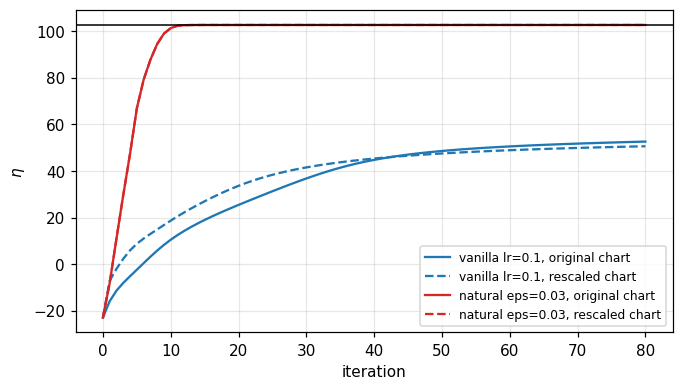

exact gradients:  max |eta(rescaled) - eta(original)|  vanilla = 11.1,  natural = 4.26e-14
sampled gradients: max |eta(rescaled) - eta(original)|  vanilla = 11.2,  natural = 3.13e-13


In [46]:
rng_scales = np.random.default_rng(123)
SCALES = np.exp(rng_scales.uniform(-np.log(CHART_SCALE_SPREAD), np.log(CHART_SCALE_SPREAD), N_PARAMS))

lr_ref  = LR_GRID[len(LR_GRID) // 2]
eps_ref = EPS_GRID[len(EPS_GRID) // 2]
n_it = min(N_ITERS_EXACT, 80)
curves = {
    f"vanilla lr={lr_ref:g}, original chart":     run_exact("vanilla", n_it, lr=lr_ref),
    f"vanilla lr={lr_ref:g}, rescaled chart":      run_exact("vanilla", n_it, lr=lr_ref, scales=SCALES),
    f"natural eps={eps_ref:g}, original chart":    run_exact("natural", n_it, eps=eps_ref),
    f"natural eps={eps_ref:g}, rescaled chart":    run_exact("natural", n_it, eps=eps_ref, scales=SCALES),
}
fig, ax = plt.subplots(figsize=(7, 3.8))
styles = ["-", "--", "-", "--"]; colors = ["C0", "C0", "C3", "C3"]
for (name, c), ls, col in zip(curves.items(), styles, colors): ax.plot(c, ls=ls, color=col, label=name)
ax.axhline(ETA_STAR, color="k", lw=1); ax.set_xlabel("iteration"); ax.set_ylabel(r"$\eta$"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.show()
k = list(curves.values())
print("exact gradients:  max |eta(rescaled) - eta(original)|  vanilla = %.3g,  natural = %.3g"
      % (np.abs(k[0] - k[1]).max(), np.abs(k[2] - k[3]).max()))

# Same test with SAMPLED gradients. Statewise damping is transformed covariantly in the chart;
# finite-sample estimates should remain invariant up to numerical/Monte Carlo effects.
v1, _ = run_sampled("vanilla", 40, 0, lr=lr_ref)
v2, _ = run_sampled("vanilla", 40, 0, lr=lr_ref, scales=SCALES)
n1, _ = run_sampled("natural", 40, 0, eps=eps_ref)
n2, _ = run_sampled("natural", 40, 0, eps=eps_ref, scales=SCALES)
print("sampled gradients: max |eta(rescaled) - eta(original)|  vanilla = %.3g,  natural = %.3g"
      % (np.abs(v1 - v2).max(), np.abs(n1 - n2).max()))

## 8. Experiment C: sampled comparison

Same batch size for both methods (`EPISODES_PER_ITER` episodes per update), `N_SEEDS` independent runs per setting, and the same grids `LR_GRID` and `EPS_GRID` as in the noise-free experiment.

For each run we also follow the **greedy route** of the final policy (argmax action in each state, no slips) and record how many bonus squares it collects. A run counts as *solved* if its
exact return $\eta$ reaches `TARGET` at some iteration. The route summary shows what the runs converge to when they do not solve the problem:
`k:n` means that $n$ runs end on a route that reaches the goal after collecting $k$ bonuses, and `fail` means that the final greedy route does not reach the goal.

In [47]:
def many_sampled(method, **kw):
    curves, routes = [], []
    for seed in range(N_SEEDS):
        curve, pi_final = run_sampled(method, N_ITERS, seed, **kw)
        reached, n_bonus, _ = greedy_route(pi_final)
        curves.append(curve); routes.append(n_bonus if reached else -1)
    return np.array(curves), np.array(routes)

def route_string(routes):
    parts = [f"{k}:{(routes == k).sum()}" for k in range(len(BONUS) + 1)]
    return " ".join(parts) + f" fail:{(routes < 0).sum()}"

t0 = time.time()
sampled = {}
for lr in LR_GRID:   sampled[("vanilla", lr)]  = many_sampled("vanilla", lr=lr)
for eps in EPS_GRID: sampled[("natural", eps)] = many_sampled("natural", eps=eps)
print(f"({time.time() - t0:.0f}s)   {N_SEEDS} seeds, {N_ITERS} updates x {EPISODES_PER_ITER} episodes each; target eta = {TARGET:.2f}, eta* = {ETA_STAR:.2f}\n")

print(f"{'method':8s} {'setting':>9s} {'final eta':>10s} {'worst':>8s} {'solved':>7s} {'median episodes to target':>26s}   final greedy routes (bonuses collected)")
for (method, hp), (C, routes) in sampled.items():
    hits = [first_hit(c, TARGET) for c in C]; solved = [h for h in hits if h is not None]
    med = f"{np.median(solved) * EPISODES_PER_ITER:.0f}" if solved else "-"
    name = "lr" if method == "vanilla" else "eps"
    print(f"{method:8s} {name+'='+format(hp, 'g'):>9s} {C[:, -1].mean():10.2f} {C[:, -1].min():8.2f} "
          f"{len(solved):4d}/{N_SEEDS:<2d} {med:>26s}   {route_string(routes)}")

(392s)   10 seeds, 15 updates x 3000 episodes each; target eta = 96.28, eta* = 102.55

method     setting  final eta    worst  solved  median episodes to target   final greedy routes (bonuses collected)
vanilla   lr=0.003     -19.60   -19.63    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla    lr=0.01     -13.71   -13.78    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla    lr=0.03      -3.53    -3.64    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla     lr=0.1      18.99    18.84    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla     lr=0.3      46.53    46.28    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla       lr=1      56.24    55.74    0/10                          -   0:0 1:0 2:0 3:0 fail:10
vanilla       lr=3      57.37    57.29    0/10                          -   0:0 1:0 2:0 3:0 fail:10
natural  eps=0.003      59.31    55.69    0/10                          -   0:0 1:5 2:0 3:0 fail:

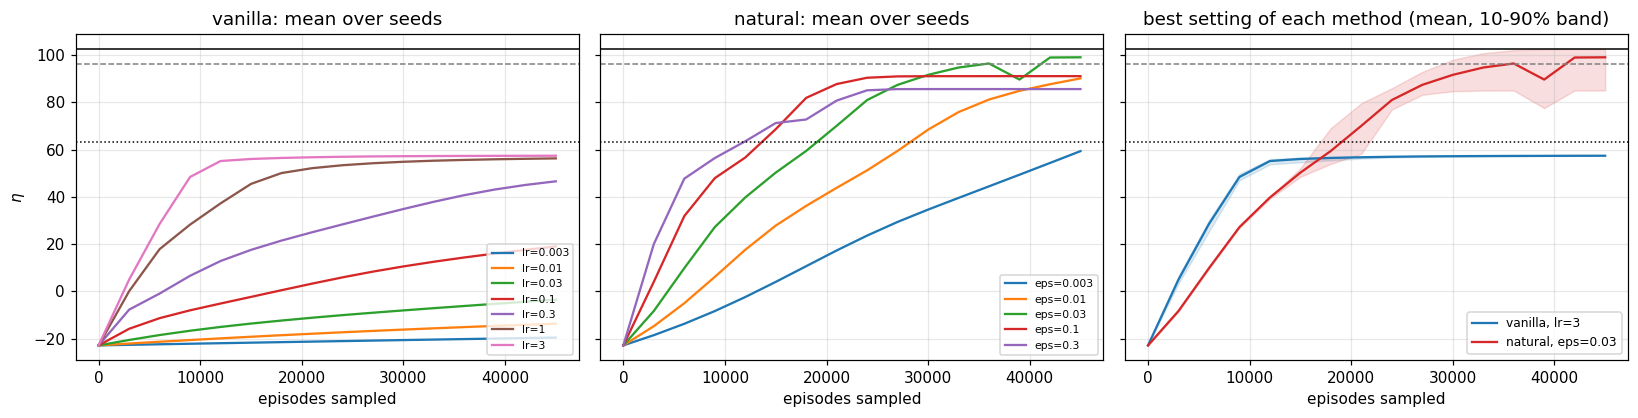

best settings by mean final return: {'vanilla': 'lr=3', 'natural': 'eps=0.03'}


In [48]:
def band(ax, C, label, **kw):
    x = np.arange(C.shape[1]) * EPISODES_PER_ITER
    mean = C.mean(0); lo, hi = np.percentile(C, [10, 90], axis=0)
    line, = ax.plot(x, mean, label=label, **kw); ax.fill_between(x, lo, hi, alpha=0.15, color=line.get_color())

# best setting of each method = highest mean final return
best = {m: max((k for k in sampled if k[0] == m), key=lambda k: sampled[k][0][:, -1].mean()) for m in ("vanilla", "natural")}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, method in zip(axes[:2], ("vanilla", "natural")):
    for k, (C, _) in sampled.items():
        if k[0] == method:
            ax.plot(np.arange(C.shape[1]) * EPISODES_PER_ITER, C.mean(0), label=f"{'lr' if method=='vanilla' else 'eps'}={k[1]:g}")
    ax.set_title(f"{method}: mean over seeds"); ax.legend(fontsize=7, loc="lower right")
for m, c in zip(("vanilla", "natural"), ("C0", "C3")):
    k = best[m]; band(axes[2], sampled[k][0], f"{m}, {'lr' if m=='vanilla' else 'eps'}={k[1]:g}", color=c)
axes[2].set_title("best setting of each method (mean, 10-90% band)")
for ax in axes:
    ax.axhline(ETA_STAR, color="k", lw=1); ax.axhline(ETA_NOBONUS, color="k", lw=1, ls=":"); ax.axhline(TARGET, color="gray", lw=1, ls="--")
    ax.set_xlabel("episodes sampled"); ax.grid(alpha=.3)
axes[2].legend(fontsize=8, loc="lower right"); axes[0].set_ylabel(r"$\eta$"); plt.tight_layout(); plt.show()
print("best settings by mean final return:", {m: f"{('lr' if m=='vanilla' else 'eps')}={k[1]:g}" for m, k in best.items()})

## 9. Things to change (all in the configuration cell)

- **Number and position of the special squares:** `LAYOUT = "random"` with `N_BONUS`, `N_PITS`, `LAYOUT_SEED`; or edit `BONUS_CELLS` / `PIT_CELLS`.
- **Size of the grid:** `ROWS`, `COLS` (the goal moves with the grid unless you set `GOAL_CELL`). The number of states grows like $\text{ROWS}\cdot\text{COLS}\cdot2^{\text{number of bonuses}}$.
- **Reward structure:** `R_STEP`, `R_GOAL`, `R_PIT`, `R_BONUS`, `GAMMA`. A large `R_BONUS` makes collecting every bonus optimal; a small one makes the goal dominate.
- **Noise:** `SLIP_PROB` (stochastic transitions), `EPISODES_PER_ITER` (smaller batches make $\hat F$ noisier), `BASELINE = "none"` (no variance reduction).
- **Starting point:** `INIT_STD > 0` starts from a random, non-uniform policy.
- **Sampled natural-gradient regularization:** `DAMPING` is the maximum ridge in a state-normalized conditional Fisher block; the code scales it as `DAMPING / sqrt(effective_visits)`. `MIN_EFFECTIVE_VISITS` controls confidence shrinkage for poorly sampled states. The ridge tends to zero as a state's sample count grows. `MAX_LOGIT_STEP` caps the actual logit change per update (`None` disables the cap).
- **Hyperparameter ranges:** `LR_GRID`, `EPS_GRID`; run lengths `N_ITERS`, `N_ITERS_EXACT`, `N_SEEDS`.